In [1]:
import pandas as pd
import numpy as np
from statsmodels.stats.inter_rater import aggregate_raters, fleiss_kappa

path1 = '../data/annotations/data_uji_kappa_Louders_Yoakim_Telaumbanua.xlsx'
path2 = '../data/annotations/data_uji_kappa_Rendy_Zikriansyah_Fauzi_Saragih.xlsx'
path3 = '../data/annotations/data_uji_kappa_Joel_Arie_Putranta_Ginting_.xlsx'

In [2]:
df1 = pd.read_excel(path1)
df2 = pd.read_excel(path2)
df3 = pd.read_excel(path3)

aspek_list = ['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'C1', 'C2', 'D1']

def encode_label(val):
    if pd.isna(val):
        return 0
    val_str = str(val).strip().capitalize()
    if val_str == 'Positif':
        return 1
    elif val_str == 'Negatif':
        return 2
    elif val_str == 'Netral':
        return 3
    return 0

kappa_per_aspek = {}

for asp in aspek_list:
    raters_matrix = pd.DataFrame({
        'Louders': df1[asp].apply(encode_label),
        'Rendy': df2[asp].apply(encode_label),
        'Joel': df3[asp].apply(encode_label)
    }).to_numpy()
    
    try:
        agg, categories = aggregate_raters(raters_matrix)
        score = fleiss_kappa(agg)
        kappa_per_aspek[asp] = score
    except Exception as e:
            kappa_per_aspek[asp] = np.nan

# Cetak hasil skor Kappa per aspek
print("Skor Fleiss' Kappa per Kategori Aspek:")
for asp, score in kappa_per_aspek.items():
    print(f"Aspek {asp}: {score:.4f}" if not np.isnan(score) else f"Aspek {asp}: Data tidak cukup/seragam")

# Rata-rata Kappa Keseluruhan Aspek
valid_scores = [s for s in kappa_per_aspek.values() if not np.isnan(s)]
if valid_scores:
    print(f"\nRata-rata Fleiss' Kappa Aspek: {sum(valid_scores)/len(valid_scores):.4f}")

Skor Fleiss' Kappa per Kategori Aspek:
Aspek A1: 0.9606
Aspek A2: 0.9269
Aspek A3: 0.9093
Aspek B1: 0.9698
Aspek B2: 1.0000
Aspek B3: 0.9621
Aspek C1: 0.9748
Aspek C2: 1.0000
Aspek D1: 0.5673

Rata-rata Fleiss' Kappa Aspek: 0.9190


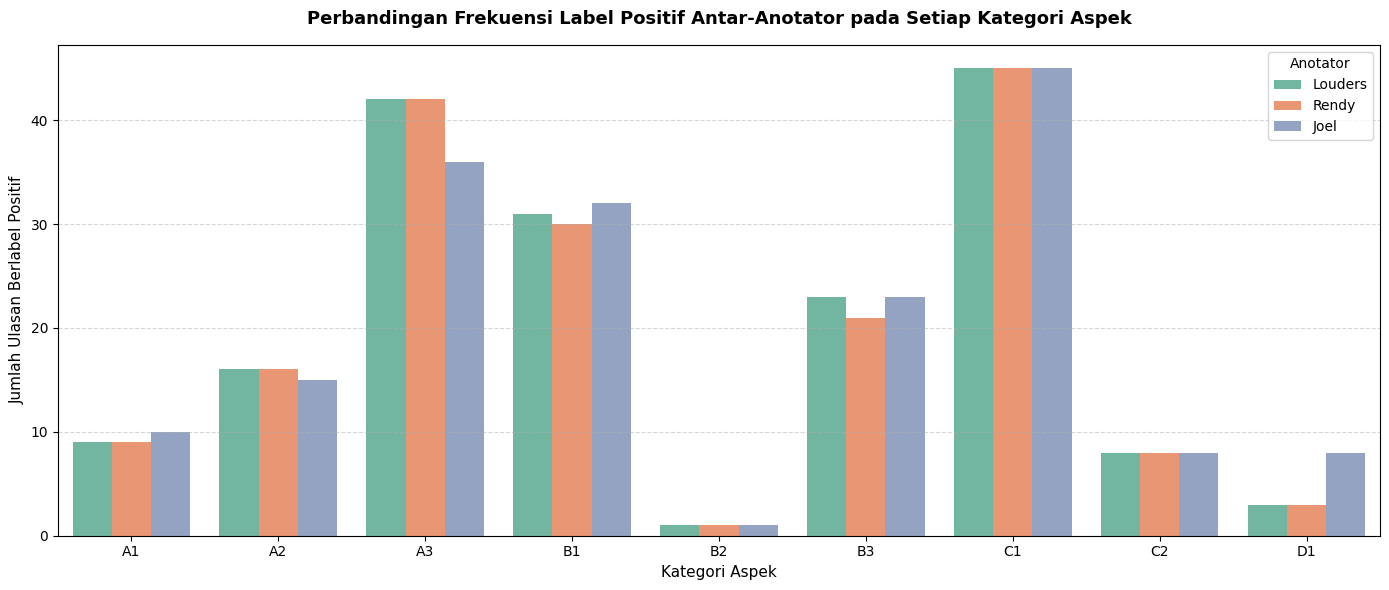

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menyiapkan data distribusi label dari ketiga anotator per aspek
aspek_list = ['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'C1', 'C2', 'D1']

def encode_label_str(val):
    if pd.isna(val):
        return 'Tidak Ada'
    val_str = str(val).strip().capitalize()
    if val_str in ['Positif', 'Negatif', 'Netral']:
        return val_str
    return 'Tidak Ada'

dist_data = []
for asp in aspek_list:
    for rater_name, df_rater in [('Louders', df1), ('Rendy', df2), ('Joel', df3)]:
        counts = df_rater[asp].apply(encode_label_str).value_counts()
        for label, count in counts.items():
            dist_data.append({
                'Aspek': asp,
                'Anotator': rater_name,
                'Label': label,
                'Jumlah': count
            })

df_dist = pd.DataFrame(dist_data)

# 2. Plotting Grouped Bar Chart Perbandingan Anotator
plt.figure(figsize=(14, 6))
sns.barplot(x='Aspek', y='Jumlah', hue='Anotator', data=df_dist[df_dist['Label'] == 'Positif'], palette='Set2')

plt.title("Perbandingan Frekuensi Label Positif Antar-Anotator pada Setiap Kategori Aspek", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Kategori Aspek", fontsize=11)
plt.ylabel("Jumlah Ulasan Berlabel Positif", fontsize=11)
plt.legend(title="Anotator", loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

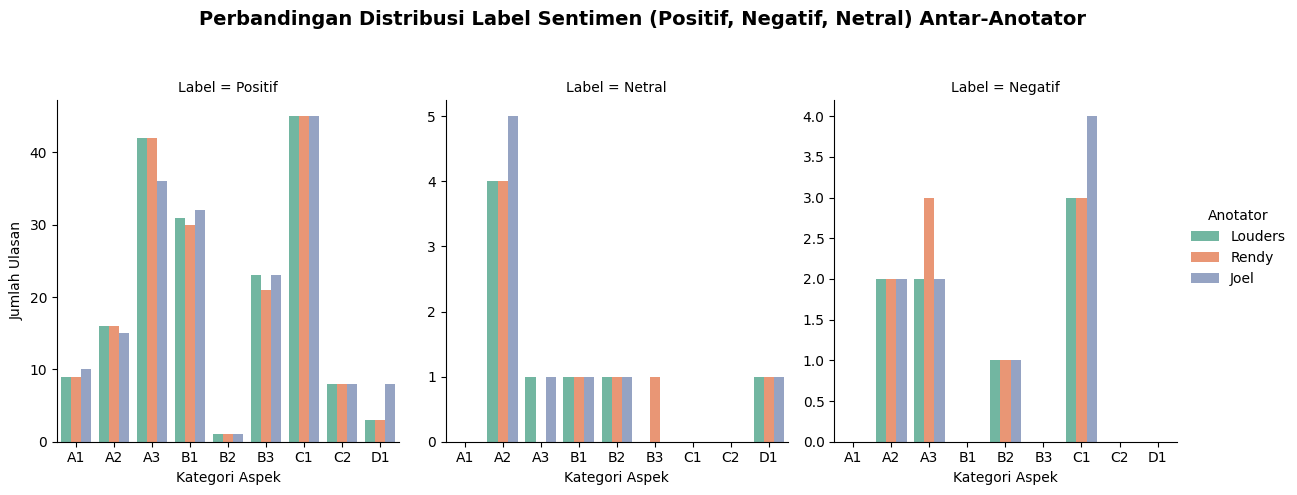

In [4]:
# Filter agar hanya mengambil label Positif, Negatif, dan Netral (buang 'Tidak Ada' agar grafik tidak terlalu panjang)
df_filtered = df_dist[df_dist['Label'].isin(['Positif', 'Negatif', 'Netral'])]

# Gunakan catplot untuk membuat multi-grafik berdasarkan Label Sentimen
g = sns.catplot(
    data=df_filtered, kind="bar",
    x="Aspek", y="Jumlah", hue="Anotator", col="Label",
    palette="Set2", height=5, aspect=0.8, sharey=False
)

g.set_axis_labels("Kategori Aspek", "Jumlah Ulasan")
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Perbandingan Distribusi Label Sentimen (Positif, Negatif, Netral) Antar-Anotator", fontsize=14, fontweight='bold')
plt.show()

In [5]:
aspek_list = ['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'C1', 'C2', 'D1']

def encode_sentiment_label(val):
    if pd.isna(val):
        return 0
    val_str = str(val).strip().capitalize()
    if val_str == 'Positif':
        return 1
    elif val_str == 'Negatif':
        return 2
    elif val_str == 'Netral':
        return 3
    return 0

kappa_sentiment_per_aspek = {}

for asp in aspek_list:
    raters_matrix = pd.DataFrame({
        'Louders': df1[asp].apply(encode_sentiment_label),
        'Rendy': df2[asp].apply(encode_sentiment_label),
        'Joel': df3[asp].apply(encode_sentiment_label) 
    }).to_numpy()
    
    try:
        agg, categories = aggregate_raters(raters_matrix)
        score = fleiss_kappa(agg)
        kappa_sentiment_per_aspek[asp] = score
    except Exception as e:
        kappa_sentiment_per_aspek[asp] = np.nan

# 4. Cetak Hasil Skor Kappa Aspek & Sentimen
print("="*60)
print("SKOR FLEISS' KAPPA (EVALUASI KATEGORI ASPEK & SENTIMEN):")
print("="*60)
for asp, score in kappa_sentiment_per_aspek.items():
    if not np.isnan(score):
        # Penentuan kategori Landis & Koch
        if score >= 0.81: interp = "Almost Perfect"
        elif score >= 0.61: interp = "Substantial"
        elif score >= 0.41: interp = "Moderate"
        else: interp = "Fair / Poor"
        print(f"Aspek {asp}: {score:.4f} ({interp})")
    else:
        print(f"Aspek {asp}: Data tidak cukup/seragam")

# 5. Rata-rata Keseluruhan
valid_scores = [s for s in kappa_sentiment_per_aspek.values() if not np.isnan(s)]
if valid_scores:
    print("-" * 60)
    print(f"Rata-rata Fleiss' Kappa Aspek & Sentimen: {sum(valid_scores)/len(valid_scores):.4f}")

SKOR FLEISS' KAPPA (EVALUASI KATEGORI ASPEK & SENTIMEN):
Aspek A1: 0.9606 (Almost Perfect)
Aspek A2: 0.9269 (Almost Perfect)
Aspek A3: 0.9093 (Almost Perfect)
Aspek B1: 0.9698 (Almost Perfect)
Aspek B2: 1.0000 (Almost Perfect)
Aspek B3: 0.9621 (Almost Perfect)
Aspek C1: 0.9748 (Almost Perfect)
Aspek C2: 1.0000 (Almost Perfect)
Aspek D1: 0.5673 (Moderate)
------------------------------------------------------------
Rata-rata Fleiss' Kappa Aspek & Sentimen: 0.9190
